In [25]:
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END

In [46]:
class GreetState(BaseModel):
    message: str = ""

In [47]:
graph=StateGraph(GreetState)

In [48]:
def Greet(state:GreetState):
    state.message=f"{state.message} ! All Good ! "
    return state

def Upper_case(state:GreetState):
    state.message.upper()
    return state

In [49]:
graph.add_node("greet", Greet)

In [50]:
graph.add_node("Upper_case", Upper_case)

In [51]:
graph.add_edge(START, "greet")
graph.add_edge("greet", "Upper_case")
graph.add_edge("Upper_case", END)

In [52]:
final_graph=graph.compile()

In [53]:
response=final_graph.invoke({"message":"I am learning LangGraph!!!"})

In [54]:
response

{'message': 'I am learning LangGraph!!! ! All Good ! '}

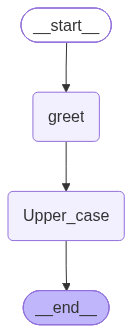

: 

In [ ]:
from IPython.display import Image
Image(final_graph.get_graph().draw_mermaid_png())